# Mejora del modelo: variables de texto, geografía y renta

El análisis por segmentos del notebook `02_modelado` mostró que la principal limitación del modelo
es la **regresión hacia la media**: sobrestima las viviendas más baratas e infravalora las más caras.
Para atacarla se añaden tres grupos de variables (`src/variables_extra.py`):

| Grupo | Variables | Fuente |
|---|---|---|
| **texto** | 13 indicadores: vistas al mar, primera línea, playa, lujo, piscina desbordante, golf, spa, ático, a estrenar, reformado, a reformar, cueva, inversión | título y descripción del anuncio |
| **geo** | distancia a la costa y a la capital de provincia | coordenadas + línea de costa (Natural Earth) |
| **renta** | renta neta media por persona del municipio (2024) | INE, Atlas de Distribución de Renta de los Hogares |

Los términos de texto se eligieron analizando los residuos fuera de muestra del modelo base
**solo en el conjunto de entrenamiento**; el de prueba no interviene en ninguna decisión. Ese análisis
reveló además anuncios de viviendas ocupadas o sin posesión que solo se identificaban por el texto;
siguiendo el criterio acordado con el tutor, se eliminan en la limpieza, igual que las marcadas en los
campos del anuncio.

Todas las métricas se expresan en euros (ver notebook 02).

Para reproducir:

```bash
python src/modelado.py --pruebas 40 --grupos texto geo renta
python src/ablacion_variables.py --grupos texto geo renta
```

Contenido:

1. Modelo base frente a modelo ampliado.
2. Aportación de cada grupo de variables (ablación).
3. Efecto sobre los extremos de precio y los segmentos.
4. Efecto de las variables de texto.
5. Explicabilidad del modelo ampliado (SHAP).
6. Redes neuronales: MLP y corrección por texto con un modelo de lenguaje.
7. Conclusiones.

Las figuras se guardan en `doc/figuras/mejora/`.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import shap

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from preprocesado import preparar  # noqa: E402
import variables_extra  # noqa: E402

RES = RAIZ / "data" / "procesado" / "resultados"
GRUPOS = ("texto", "geo", "renta")
RES_AMP = RES / "_".join(GRUPOS)
FIGURAS = RAIZ / "doc" / "figuras" / "mejora"
FIGURAS.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, REJILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})
NOMBRES = {"lineal": "Regresión lineal", "random_forest": "Random Forest", "xgboost": "XGBoost",
           "lightgbm": "LightGBM", "catboost": "CatBoost"}

def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png")
    plt.show()

res_base = pd.read_csv(RES / "resultados_modelos.csv")
res_amp = pd.read_csv(RES_AMP / "resultados_modelos.csv")
pred_base = pd.read_csv(RES / "predicciones_prueba.csv", dtype={"id_anuncio": str})
pred_amp = pd.read_csv(RES_AMP / "predicciones_prueba.csv", dtype={"id_anuncio": str})
assert (pred_base["id_anuncio"].values == pred_amp["id_anuncio"].values).all()  # mismo conjunto de prueba
MEJOR_BASE = res_base.sort_values("CV_RMSE_log").iloc[0]["modelo"]
MEJOR = res_amp.sort_values("CV_RMSE_log").iloc[0]["modelo"]
print("Mejor modelo base:", NOMBRES[MEJOR_BASE], "| mejor modelo ampliado:", NOMBRES[MEJOR])

Mejor modelo base: LightGBM | mejor modelo ampliado: LightGBM


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Modelo base frente a modelo ampliado

Cada modelo se vuelve a ajustar con Optuna (40 pruebas) con las variables nuevas, con el mismo
procedimiento, las mismas particiones de validación cruzada y el mismo conjunto de prueba.

In [2]:
cols = {"CV_MAE_eur": "MAE € (CV)", "CV_R2_eur": "R² (CV)", "test_MAE_eur": "MAE €",
        "test_RMSE_eur": "RMSE €", "test_MdAPE_pct": "MdAPE %", "test_R2_eur": "R²"}
comp = pd.concat({"base": res_base.set_index("modelo")[list(cols)],
                  "ampliado": res_amp.set_index("modelo")[list(cols)]}, axis=1)
comp = comp.rename(columns=cols, level=1).rename(index=NOMBRES)
comp = comp.reindex(comp[("ampliado", "MAE € (CV)")].sort_values().index)
for c in cols.values():
    comp[("cambio", c)] = comp[("ampliado", c)] - comp[("base", c)]
comp = comp[[(g, c) for c in cols.values() for g in ("base", "ampliado", "cambio")]]
comp.round(3)

,base,ampliado,cambio,base,ampliado,cambio,base,ampliado,cambio,base,ampliado,cambio,base,ampliado,cambio,base,ampliado,cambio
,MAE € (CV),MAE € (CV),MAE € (CV),R² (CV),R² (CV),R² (CV),MAE €,MAE €,MAE €,RMSE €,RMSE €,RMSE €,MdAPE %,MdAPE %,MdAPE %,R²,R²,R²
modelo,,,,,,,,,,,,,,,,,,
LightGBM,78091.141,72296.127,-5795.014,0.752,0.783,0.031,81199.179,74836.240,-6362.939,180856.598,173764.687,-7091.911,16.409,14.661,-1.748,0.738,0.758,0.020
XGBoost,78642.242,73238.830,-5403.412,0.743,0.771,0.029,79169.011,75787.347,-3381.664,177458.592,174853.593,-2604.999,16.336,15.231,-1.105,0.748,0.755,0.007
CatBoost,78862.686,73747.185,-5115.502,0.752,0.769,0.017,82957.441,78009.585,-4947.856,182761.433,178689.239,-4072.194,16.920,15.974,-0.946,0.732,0.744,0.012
Random Forest,83404.635,79408.077,-3996.559,0.714,0.718,0.004,85820.777,83104.653,-2716.124,195224.494,195883.666,659.172,17.564,16.147,-1.418,0.695,0.693,-0.002
Regresión lineal,101042.127,93573.028,-7469.099,0.644,0.684,0.040,104680.732,98178.579,-6502.153,220437.902,209704.426,-10733.476,23.040,21.231,-1.810,0.611,0.648,0.037


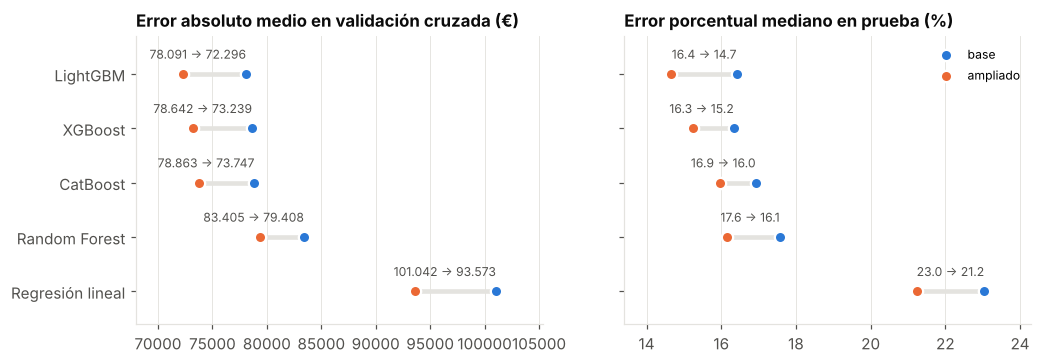

In [3]:
orden = res_amp.set_index("modelo").sort_values("CV_RMSE_log", ascending=False).index
b = res_base.set_index("modelo").loc[orden]
a = res_amp.set_index("modelo").loc[orden]
y = np.arange(len(orden))
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.4), sharey=True)
for eje, col, titulo, fmt in [(ax[0], "CV_MAE_eur", "Error absoluto medio en validación cruzada (€)", "{:,.0f}"),
                              (ax[1], "test_MdAPE_pct", "Error porcentual mediano en prueba (%)", "{:.1f}")]:
    eje.hlines(y, a[col], b[col], color=REJILLA, linewidth=3, zorder=1)
    eje.scatter(b[col], y, color=AZUL, s=55, zorder=3, edgecolor="white", linewidth=1.5, label="base")
    eje.scatter(a[col], y, color=NARANJA, s=55, zorder=3, edgecolor="white", linewidth=1.5, label="ampliado")
    for yi, (vb, va) in enumerate(zip(b[col], a[col])):
        eje.text(max(vb, va), yi + 0.28, f"{fmt.format(vb)} → {fmt.format(va)}".replace(",", "."), fontsize=8, color=TINTA_2,
                 ha="right")
    eje.set(title=titulo); eje.grid(axis="y", visible=False)
    eje.margins(x=0.15)
ax[0].set_yticks(y, [NOMBRES[m] for m in orden]); ax[0].set_ylim(-0.6, len(orden) - 0.3)
ax[1].legend(loc="upper right", fontsize=8)
guardar(fig, "01_base_vs_ampliado")

**Todos los modelos mejoran con las variables nuevas.**

- En **LightGBM**, que sigue siendo el mejor modelo:
  - el MAE de validación cruzada baja de 78.091 € a 72.296 € (−7,4 %) y el R² sube de 0,752 a 0,783;
  - en prueba, el MAE baja de 81.199 € a 74.836 € (−7,8 %), la MdAPE de 16,4 % a 14,7 % y el R² sube de 0,738 a 0,758.
- La **regresión lineal** es la que más gana en términos absolutos. Las distancias recogen relaciones que antes solo se podían aproximar a partir de la latitud y la longitud.
- **Random Forest** apenas mejora.
- Los tres modelos de *boosting* siguen muy próximos entre sí. LightGBM es el mejor tanto en validación cruzada como en prueba.

## 2. Aportación de cada grupo de variables (ablación)

Con los hiperparámetros del mejor modelo ampliado fijos, se entrena el modelo con distintas
combinaciones de grupos: cada grupo añadido al modelo base y cada grupo retirado del modelo completo
(su aportación **marginal**). La decisión se toma sobre la validación cruzada; el conjunto de
prueba, de 1.368 viviendas, tiene más ruido para diferencias pequeñas.

In [4]:
ab = pd.read_csv(RES / "ablacion_variables.csv").set_index("variante")
ab[["n_variables", "CV_MAE_eur", "CV_MAE_eur_desv", "CV_R2_eur", "test_MAE_eur", "test_MdAPE_pct", "test_R2_eur",
    "sesgo_Q1_pct", "sesgo_Q5_pct"]].round(3)

,n_variables,CV_MAE_eur,CV_MAE_eur_desv,CV_R2_eur,test_MAE_eur,test_MdAPE_pct,test_R2_eur,sesgo_Q1_pct,sesgo_Q5_pct
variante,,,,,,,,,
base,62,77888.906,6809.411,0.759,79694.726,16.489,0.745,16.580,-13.893
base + texto,75,75253.272,5582.990,0.769,78024.160,15.992,0.753,16.299,-14.795
base + geo,64,74582.533,6959.074,0.767,76589.968,14.613,0.760,12.825,-13.341
base + renta,63,77374.201,6875.011,0.753,79338.190,16.125,0.748,16.378,-13.730
todas,78,72296.127,5957.964,0.783,74836.240,14.661,0.758,13.022,-13.559
todas - texto,65,74747.666,6480.712,0.767,77759.062,15.074,0.753,14.160,-13.498
todas - geo,76,75786.274,6041.295,0.767,77883.959,15.741,0.756,15.745,-13.455
todas - renta,77,73163.269,5225.350,0.779,76453.631,15.247,0.758,14.086,-14.369


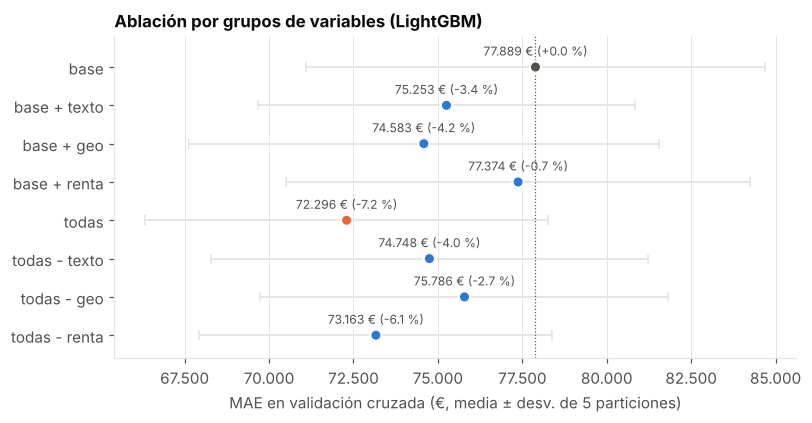

In [5]:
t = ab.iloc[::-1]
y = np.arange(len(t))
ref = ab.loc["base", "CV_MAE_eur"]
colores = [NARANJA if v == "todas" else (TINTA_2 if v == "base" else AZUL) for v in t.index]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(t["CV_MAE_eur"], y, xerr=t["CV_MAE_eur_desv"], fmt="none", ecolor=REJILLA, capsize=3, linewidth=1.2)
ax.scatter(t["CV_MAE_eur"], y, color=colores, s=55, zorder=3, edgecolor="white", linewidth=1.5)
for yi, v in enumerate(t["CV_MAE_eur"]):
    ax.text(v, yi + 0.3, f"{v:,.0f} € ({(v / ref - 1) * 100:+.1f} %)".replace(",", "."), fontsize=8, color=TINTA_2,
            ha="center")
ax.axvline(ref, color=TINTA_2, linewidth=0.8, linestyle=":")
ax.set_yticks(y, t.index); ax.grid(axis="y", visible=False); ax.set_ylim(-0.6, len(t) - 0.2)
ax.set(title=f"Ablación por grupos de variables ({NOMBRES[MEJOR]})",
       xlabel="MAE en validación cruzada (€, media ± desv. de 5 particiones)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
guardar(fig, "02_ablacion_grupos")

- **Geografía** (distancia a la costa y a la capital) es el grupo que más aporta:
  - añadida al modelo base, reduce el MAE de validación cruzada un 4,2 %;
  - retirada del modelo completo, lo empeora un 4,8 %.
- **Texto** aporta algo menos: −3,4 % añadido al base y +3,4 % al retirarlo.
- Los efectos de ambos grupos son **aproximadamente aditivos**: con todas las variables, la reducción llega al 7,2 %.
- **La renta municipal aporta poco**: −0,7 % sola y +1,2 % al retirarla. Es información de nivel municipal, en buena parte redundante con lo que el modelo ya sabe del municipio (coordenadas, población, valor medio del MIVAU).
- La fila «base» de esta tabla usa los hiperparámetros del modelo ampliado. Por eso difiere ligeramente del modelo base ajustado por separado.
- Las diferencias en prueba son coherentes con las de validación cruzada, pero más ruidosas. Las decisiones se basan en la validación cruzada.

## 3. Efecto sobre los extremos de precio y los segmentos

Se compara el mejor modelo base con el mejor modelo ampliado sobre las mismas viviendas de prueba,
con los mismos tramos de precio del notebook 02.

In [6]:
def preparar_errores(pred, modelo):
    p = pred[["id_anuncio", "provincia", "tipo_vivienda", "es_capital", "precio_eur"]].copy()
    p["pred"] = pred[f"pred_{modelo}"]
    p["error_rel"] = p["pred"] / p["precio_eur"] - 1
    p["ape"] = p["error_rel"].abs()
    return p

pb, pa = preparar_errores(pred_base, MEJOR_BASE), preparar_errores(pred_amp, MEJOR)
cortes = np.quantile(pb["precio_eur"], np.linspace(0, 1, 6))
etiquetas = [f"Q{i + 1}: {a/1000:,.0f}–{b/1000:,.0f} mil €".replace(",", ".") for i, (a, b) in
             enumerate(zip(cortes[:-1], cortes[1:]))]
for p in (pb, pa):
    p["tramo_precio"] = pd.cut(p["precio_eur"], cortes, labels=etiquetas, include_lowest=True)
    p["grupo"] = np.where(p["tipo_vivienda"] == "casa", "Casas", "Pisos y otros")
    p["localizacion"] = np.where(p["es_capital"].astype(str).str.lower().isin(["1", "true"]),
                                 "Capital", "Resto de municipios")

def resumen(col):
    f = lambda p: p.groupby(col, observed=True).agg(
        viviendas=("ape", "size"), MdAPE_pct=("ape", lambda s: s.median() * 100),
        sesgo_pct=("error_rel", lambda s: s.median() * 100))
    return pd.concat({"base": f(pb), "ampliado": f(pa)}, axis=1).round(1)

tramos = resumen("tramo_precio")
tramos

base                      ampliado            \
                    viviendas MdAPE_pct sesgo_pct viviendas MdAPE_pct   
tramo_precio                                                            
Q1: 25–133 mil €          275      20.7      16.3       275      19.1   
Q2: 133–199 mil €         270      14.5      -0.4       270      13.0   
Q3: 199–280 mil €         279      12.8      -0.5       279      10.4   
Q4: 280–434 mil €         265      14.2      -0.1       265      13.6   
Q5: 434–3.695 mil €       273      21.5     -15.1       273      20.0   

                               
                    sesgo_pct  
tramo_precio                   
Q1: 25–133 mil €         13.0  
Q2: 133–199 mil €         1.4  
Q3: 199–280 mil €        -0.7  
Q4: 280–434 mil €        -2.1  
Q5: 434–3.695 mil €     -13.6

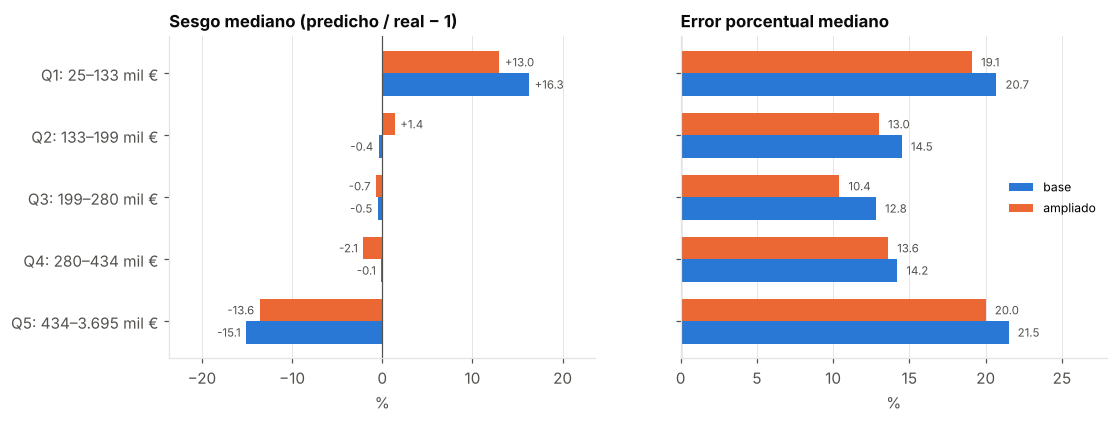

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
y = np.arange(len(tramos))
h = 0.36
for eje, col, titulo in [(ax[0], "sesgo_pct", "Sesgo mediano (predicho / real − 1)"),
                         (ax[1], "MdAPE_pct", "Error porcentual mediano")]:
    for desp, (g, color) in zip((h / 2, -h / 2), [("base", AZUL), ("ampliado", NARANJA)]):
        v = tramos[(g, col)]
        eje.barh(y + desp, v, height=h, color=color, label=g)
        for yi, vi in zip(y + desp, v):
            eje.text(vi + (0.6 if vi >= 0 else -0.6), yi, f"{vi:+.1f}" if col == "sesgo_pct" else f"{vi:.1f}",
                     va="center", ha="left" if vi >= 0 else "right", fontsize=7.5, color=TINTA_2)
    eje.axvline(0, color=TINTA_2, linewidth=0.8)
    eje.set(title=titulo, xlabel="%"); eje.grid(axis="y", visible=False)
lim = tramos.xs("sesgo_pct", axis=1, level=1).abs().max().max() * 1.45
ax[0].set_xlim(-lim, lim); ax[1].set_xlim(0, tramos.xs("MdAPE_pct", axis=1, level=1).max().max() * 1.3)
ax[0].set_yticks(y, tramos.index); ax[0].invert_yaxis()
ax[1].legend(loc="center right", fontsize=8)
guardar(fig, "03_extremos_base_vs_ampliado")

In [8]:
segm = pd.concat({"Tipo": resumen("grupo"), "Localización": resumen("localizacion"),
                  "Provincia": resumen("provincia")})
segm

base                      ampliado  \
                                 viviendas MdAPE_pct sesgo_pct viviendas   
Tipo         Casas                     559      19.9       0.3       559   
             Pisos y otros             803      14.5       0.2       803   
Localización Capital                   331      15.8      -3.5       331   
             Resto de municipios      1031      16.6       1.6      1031   
Provincia    Almería                   129      14.0      -2.6       129   
             Cádiz                     242      14.8       0.3       242   
             Córdoba                   146      20.6       2.0       146   
             Granada                   125      13.2      -1.4       125   
             Huelva                    109      17.6      -2.0       109   
             Jaén                      165      19.4      -5.1       165   
             Málaga                    329      16.0       4.7       329   
             Sevilla                   117      16.1       0.6       117   

                                                      
                                 MdAPE_pct sesgo_pct  
Tipo         Casas                    16.5      -1.2  
             Pisos y otros            13.7      -0.6  
Localización Capital                  14.1      -2.9  
             Resto de municipios      14.8       0.6  
Provincia    Almería                  13.0      -1.9  
             Cádiz                    13.8      -0.7  
             Córdoba                  17.3       1.9  
             Granada                  12.3      -3.1  
             Huelva                   12.1      -0.9  
             Jaén                     19.4      -5.2  
             Málaga                   14.7       2.4  
             Sevilla                  15.9      -1.1

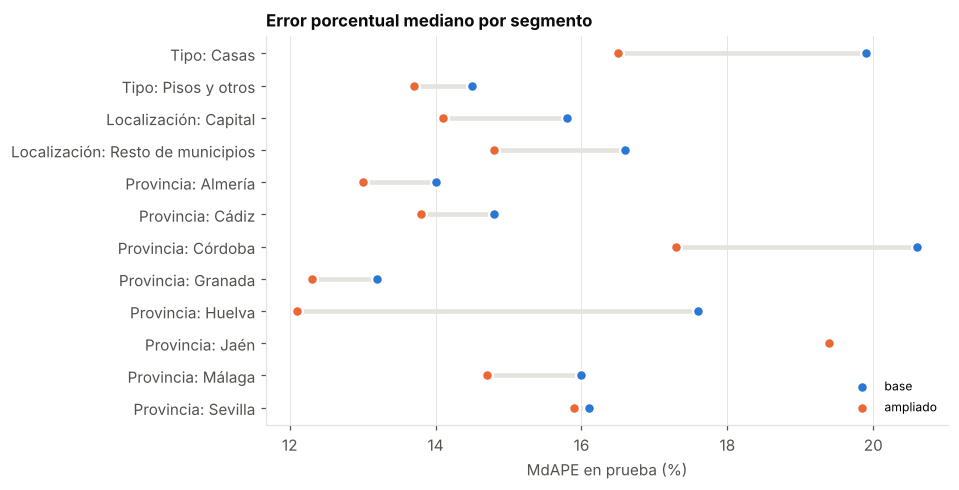

In [9]:
t = segm.iloc[::-1]
y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hlines(y, t[("ampliado", "MdAPE_pct")], t[("base", "MdAPE_pct")], color=REJILLA, linewidth=3, zorder=1)
ax.scatter(t[("base", "MdAPE_pct")], y, color=AZUL, s=50, zorder=3, edgecolor="white", linewidth=1.5, label="base")
ax.scatter(t[("ampliado", "MdAPE_pct")], y, color=NARANJA, s=50, zorder=3, edgecolor="white", linewidth=1.5,
           label="ampliado")
ax.set_yticks(y, [f"{g}: {v}" for g, v in t.index]); ax.grid(axis="y", visible=False)
ax.set(title="Error porcentual mediano por segmento", xlabel="MdAPE en prueba (%)")
ax.legend(loc="lower right", fontsize=8)
guardar(fig, "04_segmentos_base_vs_ampliado")

**El error baja en todos los tramos de precio, pero el sesgo de los extremos solo se reduce en parte.**

- La MdAPE mejora en todos los quintiles. La mejora es mayor en los tramos centrales: en Q3 pasa de 12,8 % a 10,4 %.
- El sesgo de los extremos baja algo: Q1 pasa de +16,3 % a +13,0 % y Q5 de −15,1 % a −13,6 %.

Las variables nuevas hacen el modelo más preciso de forma general, pero no eliminan la regresión hacia la media. Ese sesgo es, en gran parte, una propiedad estadística de cualquier predictor imperfecto cuando se agrupa por el **precio real**. Si una vivienda está muy por encima de lo que explican sus características (calidades interiores, reforma de lujo, un precio de salida optimista), el modelo no puede saberlo. Al agrupar por precio real, esos casos se concentran en el quintil superior, y los opuestos en el inferior.

Por segmentos:

- La mejora más clara es en **casas** (19,9 % → 16,5 %), que se acercan a los pisos (14,5 % → 13,7 %).
- También mejoran mucho **Huelva** (17,6 % → 12,1 %), provincia con un fuerte contraste entre costa e interior, y **Córdoba** (20,6 % → 17,3 %).
- **Jaén**, completamente de interior, no cambia (19,4 %) y pasa a ser la provincia peor predicha. Es coherente con que la distancia a la costa sea la variable nueva más importante.

## 4. Efecto de las variables de texto

Para cada indicador de texto se compara el sesgo mediano del modelo base y del ampliado en las
viviendas de prueba que lo contienen. Si la variable recoge información que antes faltaba, el sesgo
de ese grupo debería acercarse a cero.

In [10]:
limpio = pd.read_csv(RAIZ / "data" / "procesado" / "fotocasa_andalucia_limpio.csv",
                     usecols=["id_anuncio", "titulo", "descripcion"], dtype={"id_anuncio": str})
txt = variables_extra.variables_texto(limpio).assign(id_anuncio=limpio["id_anuncio"])
pt = pb[["id_anuncio", "error_rel"]].rename(columns={"error_rel": "base"}).assign(ampliado=pa["error_rel"].values)
pt = pt.merge(txt, on="id_anuncio", how="left")
filas = []
for v in variables_extra.VARIABLES_TEXTO:
    s = pt[pt[v] == 1]
    filas.append(dict(variable=v.removeprefix("txt_").replace("_", " "), viviendas=len(s),
                      sesgo_base_pct=s["base"].median() * 100, sesgo_ampliado_pct=s["ampliado"].median() * 100))
efecto_txt = pd.DataFrame(filas).set_index("variable").sort_values("sesgo_base_pct")
efecto_txt.round(1)

,viviendas,sesgo_base_pct,sesgo_ampliado_pct
variable,,,
piscina desbordante,10,-28.5,-18.8
lujo,95,-8.2,-0.2
reformado,171,-3.7,-1.4
primera linea,50,-3.6,2.6
vistas mar,91,-3.5,-2.2
a estrenar,41,-1.7,-0.6
playa,311,-0.5,1.5
spa,123,-0.2,0.6
inversion,368,2.0,-0.3


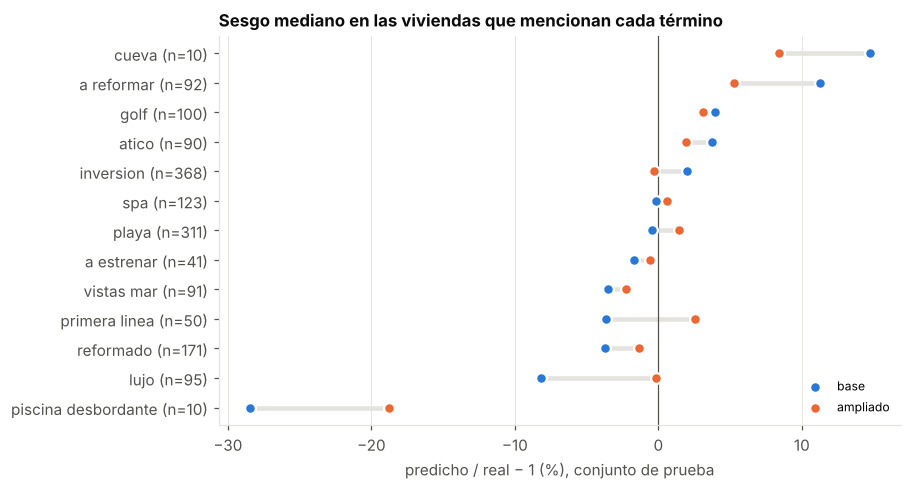

In [11]:
t = efecto_txt[efecto_txt["viviendas"] >= 10]
y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hlines(y, t["sesgo_ampliado_pct"], t["sesgo_base_pct"], color=REJILLA, linewidth=3, zorder=1)
ax.scatter(t["sesgo_base_pct"], y, color=AZUL, s=50, zorder=3, edgecolor="white", linewidth=1.5, label="base")
ax.scatter(t["sesgo_ampliado_pct"], y, color=NARANJA, s=50, zorder=3, edgecolor="white", linewidth=1.5,
           label="ampliado")
ax.axvline(0, color=TINTA_2, linewidth=0.8)
ax.set_yticks(y, [f"{i} (n={n})" for i, n in zip(t.index, t["viviendas"])]); ax.grid(axis="y", visible=False)
ax.set(title="Sesgo mediano en las viviendas que mencionan cada término",
       xlabel="predicho / real − 1 (%), conjunto de prueba")
ax.legend(loc="lower right", fontsize=8)
guardar(fig, "05_sesgo_por_termino")

Las variables de texto corrigen el sesgo de los grupos para los que se diseñaron:

- **Lujo** (n = 95): pasa de una infravaloración del 8,2 % a prácticamente cero (−0,2 %).
- **A reformar** (n = 92): la sobrestimación baja de +11,2 % a +5,3 %.
- **Reformado** y **vistas al mar**: el sesgo se reduce a menos del 2,5 %.
- **Piscina desbordante** (n = 10): pasa de −28,5 % a −18,8 %.
- **Cueva** (n = 10): pasa de +14,7 % a +8,4 %.

En **primera línea** (n = 50), el modelo pasa de infravalorar (−3,6 %) a sobrestimar ligeramente (+2,6 %). Probablemente se suman dos señales que recogen lo mismo, el término de texto y la distancia a la costa casi nula.

Los grupos con 10 viviendas en prueba deben leerse con cautela.

Los términos se eligieron con los residuos del modelo base sobre el mismo conjunto de entrenamiento con el que luego se hace la validación cruzada. Esto puede hacer la estimación de validación cruzada ligeramente optimista. El conjunto de prueba, que no intervino en la selección, confirma la mejora (MAE −7,8 %).

## 5. Explicabilidad del modelo ampliado (SHAP)

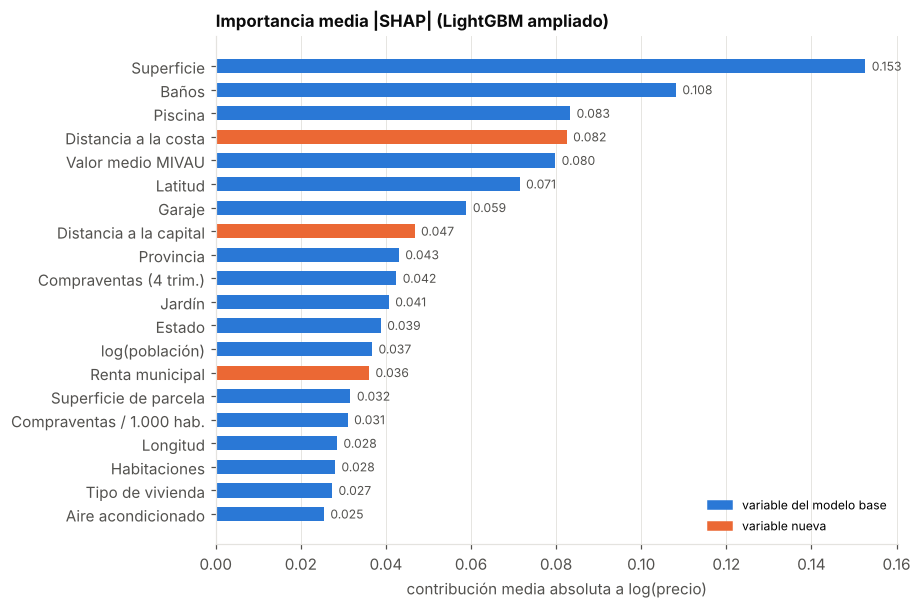

Peso de las variables nuevas en la importancia total: 20.0 %


,% del total
dist_costa_km,6.3
dist_capital_km,3.5
renta_neta_persona,2.7
txt_lujo,1.6
txt_playa,1.4
txt_inversion,1.0
txt_primera_linea,0.6
txt_a_reformar,0.6
txt_vistas_mar,0.6
txt_spa,0.6


In [12]:
X_train, X_test, y_train, y_test, ctx = preparar(grupos=GRUPOS)
modelo = joblib.load(RAIZ / "models" / "_".join(GRUPOS) / f"{MEJOR}.joblib")
assert np.allclose(np.exp(modelo.predict(X_test)), pred_amp[f"pred_{MEJOR}"], rtol=1e-6)  # mismo modelo
valores = shap.TreeExplainer(modelo)(X_test)
shap_df = pd.DataFrame(valores.values, columns=X_test.columns)

def variable_original(c):
    if c == "log_superficie":
        return "superficie_m2"
    for pref in ["tipo_vivienda_", "estado_", "orientacion_", "provincia_"]:
        if c.startswith(pref):
            return pref[:-1]
    return c

grupos_col = pd.Series([variable_original(c) for c in X_test.columns], index=X_test.columns)
importancia = shap_df.abs().T.groupby(grupos_col).sum().T.mean().sort_values()
NUEVAS = set(v for g in GRUPOS for v in variables_extra.GRUPOS[g])
NOMBRES_VAR = {
    "superficie_m2": "Superficie", "banos": "Baños", "habitaciones": "Habitaciones", "latitud": "Latitud",
    "longitud": "Longitud", "mivau_valor_medio_ref_eur": "Valor medio MIVAU",
    "mivau_trans_por_1000hab": "Compraventas / 1.000 hab.", "mivau_trans_total_4t": "Compraventas (4 trim.)",
    "log_poblacion": "log(población)", "antiguedad_anos": "Antigüedad", "planta_num": "Planta",
    "superficie_terreno_m2": "Superficie de parcela", "tipo_vivienda": "Tipo de vivienda", "estado": "Estado",
    "orientacion": "Orientación", "provincia": "Provincia", "es_capital": "Capital", "piscina": "Piscina",
    "ascensor": "Ascensor", "terraza": "Terraza", "parking": "Garaje", "jardin": "Jardín",
    "aire_acondicionado": "Aire acondicionado", "trastero": "Trastero", "obra_nueva": "Obra nueva",
    "dist_costa_km": "Distancia a la costa", "dist_capital_km": "Distancia a la capital",
    "renta_neta_persona": "Renta municipal",
}
nombre_var = lambda v: NOMBRES_VAR.get(v, v.replace("txt_", "texto: ").replace("_", " "))

top = importancia.tail(20)
fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(top))
ax.barh(y, top.values, color=[NARANJA if v in NUEVAS else AZUL for v in top.index], height=0.6)
for yi, v in enumerate(top.values):
    ax.text(v + top.max() * 0.01, yi, f"{v:.3f}", va="center", fontsize=8, color=TINTA_2)
ax.set_yticks(y, [nombre_var(i) for i in top.index]); ax.grid(axis="y", visible=False)
ax.set(title=f"Importancia media |SHAP| ({NOMBRES[MEJOR]} ampliado)",
       xlabel="contribución media absoluta a log(precio)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=AZUL), plt.Rectangle((0, 0), 1, 1, color=NARANJA)],
          labels=["variable del modelo base", "variable nueva"], loc="lower right", fontsize=8)
guardar(fig, "06_importancia_shap_ampliado")
cuota = importancia / importancia.sum() * 100
print(f"Peso de las variables nuevas en la importancia total: {cuota[cuota.index.isin(NUEVAS)].sum():.1f} %")
(cuota.sort_values(ascending=False)[lambda s: s.index.isin(NUEVAS)]).round(1).to_frame("% del total")

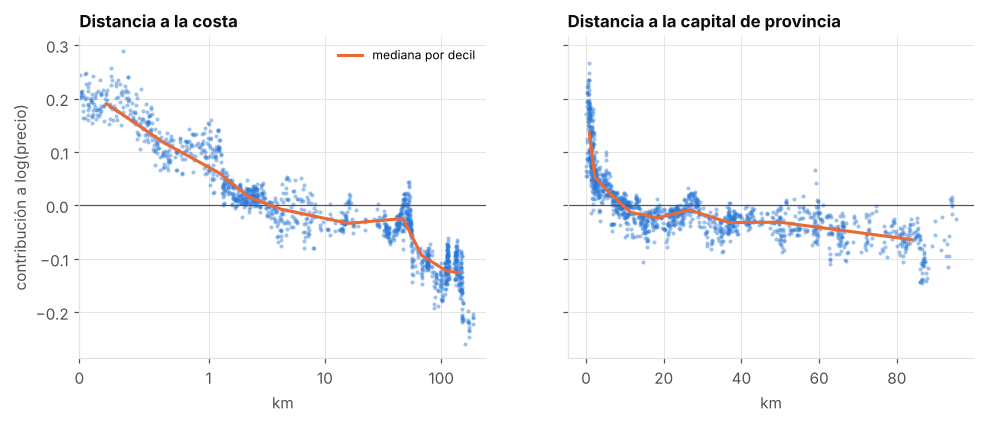

Efecto mediano de la costa a ≤1 km: +16.7%
Efecto mediano de la costa a ~5 km: -1.5%
Efecto mediano de la costa a ~20 km: -3.0%
Efecto mediano de la costa a ~60 km: -3.5%


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for eje, var, titulo in [(ax[0], "dist_costa_km", "Distancia a la costa"),
                         (ax[1], "dist_capital_km", "Distancia a la capital de provincia")]:
    eje.scatter(X_test[var], shap_df[var], s=7, alpha=0.45, color=AZUL, linewidth=0)
    eje.axhline(0, color=TINTA_2, linewidth=0.8)
    eje.set(title=titulo, xlabel="km")
    # efecto mediano por tramo de distancia, para leer la tendencia
    tramos_d = pd.cut(X_test[var], np.quantile(X_test[var].dropna(), np.linspace(0, 1, 11)), include_lowest=True)
    m = pd.DataFrame({"x": X_test[var], "s": shap_df[var]}).groupby(tramos_d, observed=True).median()
    eje.plot(m["x"], m["s"], color=NARANJA, linewidth=2, label="mediana por decil")
ax[0].set_xscale("symlog", linthresh=1); ax[0].set_xlim(0, X_test["dist_costa_km"].max() * 1.3); ax[0].xaxis.set_major_formatter(mticker.ScalarFormatter())
ax[0].set_ylabel("contribución a log(precio)"); ax[0].legend(fontsize=8)
guardar(fig, "07_dependencia_distancias")
for d in (1, 5, 20, 60):
    s = shap_df.loc[X_test["dist_costa_km"] <= d, "dist_costa_km"].median() if d == 1 else \
        shap_df.loc[X_test["dist_costa_km"].between(d * 0.8, d * 1.2), "dist_costa_km"].median()
    print(f"Efecto mediano de la costa a {'≤' if d == 1 else '~'}{d} km: {np.exp(s) - 1:+.1%}")

Las variables nuevas suman el **20 % de la importancia total** del modelo.

- **Distancia a la costa** (4.ª variable más importante, al nivel de la piscina y del valor medio del MIVAU):
  - estar a menos de 1 km de la costa aporta en torno a un **+17 %** al precio predicho, y algo más en primera línea;
  - el efecto se anula hacia los 3–5 km y es ligeramente negativo hasta unos 50 km;
  - a partir de ahí cae hasta cerca de un −12 % en el interior profundo, a más de 100 km.
- **Distancia a la capital de provincia** (8.ª): las viviendas a 1–2 km del centro de la capital reciben entre un +15 % y un +25 %. El efecto es neutro a partir de unos 10 km y negativo de forma suave con la distancia, hasta cerca de un −6 % a 80 km.
- **Renta municipal** (14.ª): el modelo la utiliza, pero su aportación a la precisión es pequeña (sección 2). Parte de su importancia la toma de otras variables municipales con las que está correlacionada. Es un recordatorio de que la importancia SHAP mide cuánto usa el modelo una variable, no cuánto mejora la predicción.
- **Variables de texto**: tienen una importancia media pequeña (la mayor es «lujo», con un 1,6 %), porque afectan a pocas viviendas. Para esas viviendas su efecto es grande, como muestra la sección anterior.

## 6. Redes neuronales

Se prueban dos usos de redes neuronales (`src/redes_neuronales.py`):

1. **MLP** (perceptrón multicapa, 3 capas ocultas de 256, 128 y 64 neuronas) con las mismas variables que
   el mejor modelo ampliado, sola y combinada con él.
2. **Corrección por texto con un modelo de lenguaje.** Cada anuncio se representa con el *embedding* de su
   título y descripción completos: un vector de 384 dimensiones calculado con el modelo preentrenado
   multilingüe `multilingual-e5-small` (`src/embeddings_texto.py`). Una regresión ridge aprende a predecir,
   a partir de ese vector, el error que comete el mejor modelo ampliado, y se suma a su predicción. El error con el que
   se entrena la ridge se calcula siempre fuera de muestra, dentro de cada partición.

```bash
python -m pip install sentence-transformers   # solo para calcular los embeddings
python src/embeddings_texto.py                # una vez (~10 min en CPU)
python src/redes_neuronales.py                # ~3 min
```

In [14]:
rn = pd.read_csv(RES_AMP / "redes_neuronales.csv").set_index("descripcion")
rn[["CV_MAE_eur", "CV_MAE_eur_desv", "CV_R2_eur", "test_MAE_eur", "test_RMSE_eur", "test_MdAPE_pct", "test_R2_eur"]].round(3)

,CV_MAE_eur,CV_MAE_eur_desv,CV_R2_eur,test_MAE_eur,test_RMSE_eur,test_MdAPE_pct,test_R2_eur
descripcion,,,,,,,
LightGBM ampliado,72296.127,5957.964,0.783,74836.240,173764.687,14.661,0.758
MLP,83620.741,4941.853,0.723,88950.654,199720.555,18.474,0.680
LightGBM + MLP (peso MLP 0.10),72243.532,5856.906,0.783,75169.282,175268.371,14.669,0.754
LightGBM ampliado + corrección por texto,71550.664,5002.656,0.797,73321.953,165888.080,15.069,0.780


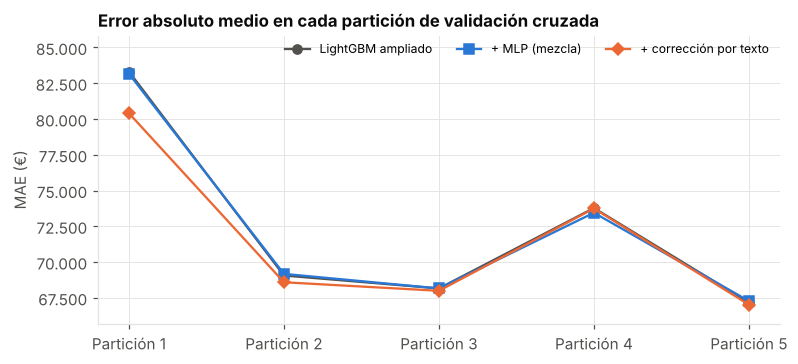

La corrección por texto mejora en 5 de 5 particiones; la mezcla con el MLP en 3 de 5.
Correlación entre los residuos de LightGBM y del MLP: 0.85


In [15]:
cols_p = [f"CV_MAE_eur_p{i}" for i in range(1, 6)]
orden = ["tabular", "mezcla", "correccion_texto"]
etiquetas_rn = {"tabular": f"{NOMBRES[MEJOR]} ampliado", "mezcla": "+ MLP (mezcla)", "correccion_texto": "+ corrección por texto"}
t = rn.reset_index().set_index("variante").loc[orden, cols_p]
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(5)
for v, color, marca in zip(orden, [TINTA_2, AZUL, NARANJA], ["o", "s", "D"]):
    ax.plot(x, t.loc[v], marker=marca, color=color, linewidth=1.5, markersize=6, label=etiquetas_rn[v])
ax.set_xticks(x, [f"Partición {i}" for i in range(1, 6)])
ax.set(title="Error absoluto medio en cada partición de validación cruzada", ylabel="MAE (€)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
ax.legend(fontsize=8, loc="upper right", ncols=3, bbox_to_anchor=(1, 1.02))
ax.set_ylim(t.min().min() * 0.98, t.max().max() * 1.03)
guardar(fig, "08_redes_por_particion")
print(f"La corrección por texto mejora en {(t.loc['correccion_texto'] < t.loc['tabular']).sum()} de 5 particiones; "
      f"la mezcla con el MLP en {(t.loc['mezcla'] < t.loc['tabular']).sum()} de 5.")
assert rn["modelo_tabular"].iloc[0] == MEJOR
print(f"Correlación entre los residuos de {NOMBRES[MEJOR]} y del MLP: {rn['corr_residuos_tabular_mlp'].iloc[0]:.2f}")

In [16]:
pc = pd.read_csv(RES_AMP / "predicciones_correccion_texto.csv", dtype={"id_anuncio": str})
assert (pc["id_anuncio"].values == pa["id_anuncio"].values).all()
pt2 = pa[["tramo_precio"]].copy()
for k in ("tabular", "correccion_texto"):
    pt2[k] = pc[f"pred_{k}"] / pc["precio_eur"] - 1
q = pd.concat({"sesgo_pct": pt2.groupby("tramo_precio", observed=True)[["tabular", "correccion_texto"]].median() * 100,
               "MdAPE_pct": pt2.groupby("tramo_precio", observed=True)[["tabular", "correccion_texto"]]
                                 .agg(lambda s: s.abs().median()) * 100}, axis=1).round(1)
q

sesgo_pct                  MdAPE_pct                 
                      tabular correccion_texto   tabular correccion_texto
tramo_precio                                                             
Q1: 25–133 mil €         13.0             12.7      19.1             19.6
Q2: 133–199 mil €         1.4             -0.0      13.0             13.3
Q3: 199–280 mil €        -0.7             -0.3      10.4             11.3
Q4: 280–434 mil €        -2.1             -1.7      13.6             14.1
Q5: 434–3.695 mil €     -13.6            -11.1      20.0             18.6

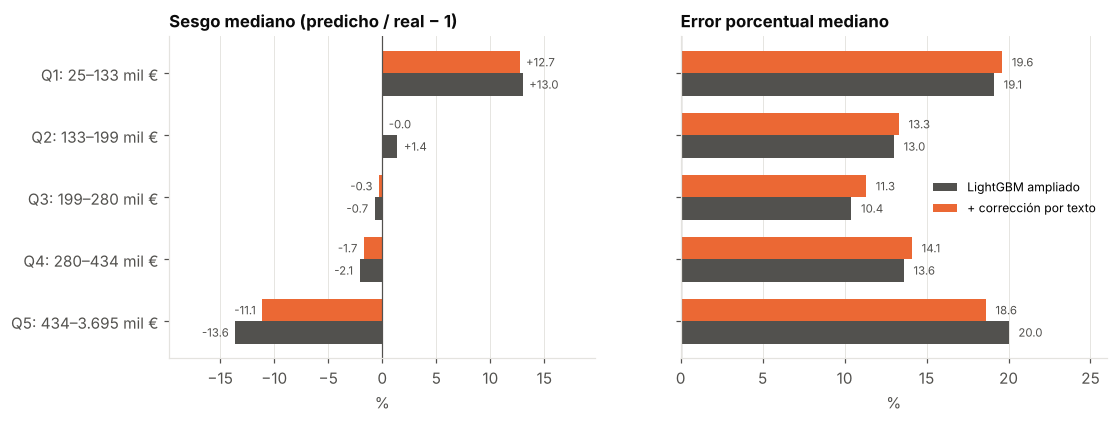

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
y = np.arange(len(q)); h = 0.36
for eje, col, titulo in [(ax[0], "sesgo_pct", "Sesgo mediano (predicho / real − 1)"),
                         (ax[1], "MdAPE_pct", "Error porcentual mediano")]:
    for desp, (g, color, et) in zip((h / 2, -h / 2), [("tabular", TINTA_2, f"{NOMBRES[MEJOR]} ampliado"),
                                                       ("correccion_texto", NARANJA, "+ corrección por texto")]):
        v = q[(col, g)]
        eje.barh(y + desp, v, height=h, color=color, label=et)
        for yi, vi in zip(y + desp, v):
            eje.text(vi + (0.6 if vi >= 0 else -0.6), yi, f"{vi:+.1f}" if col == "sesgo_pct" else f"{vi:.1f}",
                     va="center", ha="left" if vi >= 0 else "right", fontsize=7.5, color=TINTA_2)
    eje.axvline(0, color=TINTA_2, linewidth=0.8); eje.set(title=titulo, xlabel="%"); eje.grid(axis="y", visible=False)
lim = q["sesgo_pct"].abs().max().max() * 1.45
ax[0].set_xlim(-lim, lim); ax[1].set_xlim(0, q["MdAPE_pct"].max().max() * 1.3)
ax[0].set_yticks(y, q.index); ax[0].invert_yaxis(); ax[1].legend(loc="center right", fontsize=8)
guardar(fig, "09_extremos_correccion_texto")

**MLP: no aporta.**

- Por sí solo queda lejos de LightGBM: MAE de 83.621 € en validación cruzada, frente a 72.296 €, y MdAPE en prueba del 18,5 %, al nivel de Random Forest.
- Para obtener un resultado útil fue imprescindible estandarizar también la variable objetivo.
- Combinado con LightGBM (peso de 0,10), el MAE de validación cruzada apenas cambia (72.244 €), mejora solo en 3 de las 5 particiones y empeora ligeramente en prueba.
- Sus errores están muy correlacionados con los de LightGBM (0,85): con las mismas variables, la red no ve nada que los árboles no capten ya. Es el resultado habitual en datos tabulares de este tamaño.

**Corrección por texto con un modelo de lenguaje: mejora consistente, sobre todo en las viviendas caras.**

- En validación cruzada, el MAE baja de 72.296 € a 71.551 € y el R² sube de 0,783 a 0,797. El criterio de ajuste mejora en las **5 particiones** (RMSE de log de 0,2832 a 0,2789).
- En prueba, el MAE baja de 74.836 € a 73.322 € (−2,0 %), el RMSE de 173.765 € a 165.888 € (−4,5 %) y el R² sube de 0,758 a 0,780.
- La mejora se concentra en el **quintil más caro**: su sesgo pasa de −13,6 % a −11,1 % y su MdAPE de 20,0 % a 18,6 %. Por eso mejoran sobre todo las métricas en euros, dominadas por esas viviendas.
- En los tramos centrales, la MdAPE empeora ligeramente (0,3–0,9 puntos). En conjunto, la MdAPE de prueba pasa de 14,7 % a 15,1 %, y en validación cruzada queda igual (15,5 % frente a 15,6 %).

Es coherente con la interpretación de la sección 3: lo que hace que una vivienda valga más de lo que indican sus metros y su ubicación (calidades, reformas, vistas) suele estar escrito en la descripción, y el modelo de lenguaje lo recoge mejor que una lista de palabras clave. Usar el *embedding* directamente como variable de entrada no mejoraba el modelo; lo que funciona es que el texto prediga el **error** del modelo tabular.

Tiene un coste práctico: predecir un anuncio nuevo exige calcular su *embedding* con el modelo de lenguaje (unos 470 MB).

## 7. Conclusiones

1. **Modelo final: LightGBM con las variables ampliadas más la corrección por texto.** Es el que mejor resultado da en el criterio de selección (validación cruzada) y en todas las métricas en euros. Respecto al modelo base del notebook 02:
   - en validación cruzada, el MAE baja de 78.091 € a 71.551 € (−8,4 %) y el R² sube de 0,752 a 0,797;
   - en prueba, el MAE baja de 81.199 € a 73.322 € (−9,7 %), el R² sube de 0,738 a 0,780 y la MdAPE baja de 16,4 % a 15,1 %.

   Si se prefiere un modelo que no dependa de un modelo de lenguaje, el LightGBM ampliado sin corrección es una alternativa muy cercana, con mejor MdAPE en prueba (14,7 %) pero peor MAE y R².
2. **Qué ha funcionado, por orden de aportación:**
   - distancia a la costa y a la capital (−4 a −5 % de MAE);
   - palabras clave de la descripción (−3,4 %);
   - corrección con el texto completo mediante un modelo de lenguaje (−1 % de MAE en validación cruzada), la que más reduce el sesgo de las viviendas caras.
3. **Qué ha funcionado poco o nada:**
   - la renta municipal (aportación de en torno al 1 %), redundante en gran parte con el contexto municipal ya disponible;
   - el MLP, que no supera a LightGBM ni aporta al combinarlo con él.
4. **Limitación que persiste:** la regresión hacia la media en los extremos de precio se reduce, pero sigue siendo notable (+13 % en el quintil inferior y −11 % en el superior). Se debe a lo que el anuncio no recoge: estado real, acabados, margen de negociación.
5. **Trabajo futuro:**
   - información visual de las **fotografías** del anuncio, con modelos de visión preentrenados;
   - ajuste fino de un modelo de lenguaje sobre las descripciones;
   - variables de entorno a escala inferior al municipio (renta por sección censal, servicios cercanos);
   - intervalos de predicción;
   - precios de **transacción** en lugar de precios de oferta.